<div align="center">

# Fixed Income Project
### Leonardo Maffei ID: 1013853; Mattia Vizzino ID: 1146276 
#### Quantitative Finance and Insurance
#### February 2026
  
    
</div>



This project provides a framework for the pricing evaluation, risk assessment, and hedging of a fixed-income instruments portfolio.

The key steps of the project are summarized as follows:

* **Yield Curve Construction**: Using raw market data (Zero Rates and Discount Factors) to construct the interpolated yield curve with the **Nelson-Siegel-Svensson (NSS)** model, followed by **Cubic Spline** interpolation for precise instrument pricing.
* **Instrument Pricing**: Development of robust functions to price a variety of fixed-income instruments, including:
    * Coupon Bonds
    * Floating Rate Notes (FRN)
    * Interest Rate Swaps (IRS)
    * ATM Semi-annual Caps (using the Bachelier model).
* **Risk Sensitivities and Hedging**: Analysis of the **DV01** (Dollar Value of a Basis Point) to evaluate portfolio sensitivity and implementation of a delta-hedge strategy to mitigate interest rate shift risks.
* **Stochastic Modeling (Hull-White)**: Calibration of the short-rate model and Monte Carlo simulation to validate analytical results against simulated paths.

In [1]:
import pandas as pd
import QuantLib as ql
import numpy as np
import matplotlib.pyplot as plt
from scipy import interpolate
from scipy.optimize import least_squares
from FI_library import get_schedule_dataframe
from scipy.interpolate import CubicSpline
from math import sqrt, exp, pi, erf

### DATA
The project relies on market data from InputData2025.xlsx, from which are obtained the zero rates and the discount factors ( from "6m-zero-curve") used to build the yield curve, and the cap quotes (from "cap-vol").

In [2]:
raw = pd.read_excel("data/InputData2025.xlsx", sheet_name="6m-zero-curve")

data = raw.loc[raw["Unnamed: 4"].notna(), [
    "6M",           # Tenor
    "Unnamed: 4",   # End Date
    "Unnamed: 5",    # Zero Rate pct (%)
    "Unnamed: 6"    # df (%)
    
]].copy()

In [3]:
data.columns = ["Tenor", "EndDate", "ZeroRate_pct", "df"]

data["ZeroRate_pct"] = (data["ZeroRate_pct"].astype(str).str.replace(" ", ".", regex=False))

data["ZeroRate_pct"] = pd.to_numeric(data["ZeroRate_pct"],errors="coerce")

data = data[data["ZeroRate_pct"].notna()]
data["ZeroRate"] = data["ZeroRate_pct"] / 100.0

In [4]:
data["EndDate"] = pd.to_datetime(pd.Series(data["EndDate"]),errors="coerce")
data = data[data["EndDate"].notna()]

settlement = pd.Timestamp("2025-12-11")
data["TTM365"] = (data["EndDate"] - settlement).dt.days / 365.0
data["TTM360"] = (data["EndDate"] - settlement).dt.days / 360.0
data = data[data["TTM365"] > 0.0]

print(data[["Tenor", "EndDate", "TTM365","TTM360", "ZeroRate", "df"]])

    Tenor    EndDate     TTM365     TTM360  ZeroRate        df
2      1D 2025-12-12   0.002740   0.002778  0.020074  0.999945
3      TN 2025-12-15   0.010959   0.011111  0.020074   0.99978
4     0X6 2026-06-15   0.509589   0.516667  0.021862  0.988921
5     1X7 2026-07-15   0.591781   0.600000  0.021636  0.987278
6     2X8 2026-08-17   0.682192   0.691667  0.021657  0.985334
7     3X9 2026-09-15   0.761644   0.772222  0.021726  0.983588
8    4X10 2026-10-15   0.843836   0.855556  0.021831  0.981747
9    5X11 2026-11-16   0.931507   0.944444  0.021872  0.979832
10   6X12 2026-12-15   1.010959   1.025000  0.021901  0.978102
11  12X18 2027-06-15   1.509589   1.530556  0.022249  0.966971
12     2Y 2027-12-15   2.010959   2.038889  0.022734  0.955312
13     3Y 2028-12-15   3.013699   3.055556  0.023813   0.93081
14     4Y 2029-12-17   4.019178   4.075000  0.024734  0.905432
15     5Y 2030-12-16   5.016438   5.086111  0.025510   0.87994
16     6Y 2031-12-15   6.013699   6.097222  0.026228  0

# Nelson-Siegel-Svensson

### NSS curve construction
NSS calibration's aim is to estimate a continuous yield curve from discrete market data points adopting a parametric functional form.
The interpolation of the interest rate curve, with the given data, is carried out with the NSS model, modeling with flexibility the term structure of the interest rates, to model the spot rate $z(t)$ as follows: 
$$z(t) = \beta_0 + \beta_1 \left( \frac{1 - e^{-T/\tau_1}}{T/\tau_1} \right) + \beta_2 \left( \frac{1 - e^{-T/\tau_1}}{T/\tau_1} - e^{-T/\tau_1} \right) + \beta_3 \left( \frac{1 - e^{-T/\tau_2}}{T/\tau_2} - e^{-T/\tau_2} \right)$$
where $\beta_0$ is the long-term rate level, $\beta_1$ is the slope of the curve, $\beta_2$ and $\beta_3$ define the curve curvature, $\tau_1$ $\tau_2$ define the position of the stationary points of the curve. 

### Optimization
The goal of optimization is to provide a set of parameters $\theta = (\beta_0, \beta_1, \beta_2, \beta_3, \tau_1, \tau_2)$ that minimizes the difference between the model rates (calculated using the NSS curve with a specific set of parameteres $\beta$ and $\tau$) and the observed market zero rates. 
The optimization process aims to minimize the residuals of the NSS for each market rate from "6m-zero-curve", defined as follows: $$r_i = y_{market}(T_i) - y_{NSS}(T_i, \theta)$$
Here, $y_{market}(T_i)$ is the zero rate and $y_{NSS}(T_i, \theta)$ is the predicted rate from the NSS.

The algorithm aims to minimize the sum of the squared residuals: $S = \sum r_i^2$

Since the NSS is non-linear, it needs an initial input, wich serves as afirst guess for the minimization algorithm. Subsequently, the solver iteratively adjusts the parameters to minimize the sum of squared residuals.



In [5]:
ttm365 = data["TTM365"].values
z_mkt = data["ZeroRate"].values

In [6]:
def nss_zero_rate(t, b0, b1, b2, b3, tau1, tau2):
    term1 = (1.0 - np.exp(-t / tau1)) / (t / tau1)
    term2 = term1 - np.exp(-t / tau1)
    term3 = (1.0 - np.exp(-t / tau2)) / (t / tau2) - np.exp(-t / tau2)
    return b0 + b1 * term1 + b2 * term2 + b3 * term3

def residuals(theta, t, z_mkt):
    b0, b1, b2, b3, tau1, tau2 = theta
    z_model = nss_zero_rate(t, b0, b1, b2, b3, tau1, tau2)
    return z_model - z_mkt

# initial values
theta0 = np.array([
    0.02,   # b0
    0.00,   # b1
   -0.10,   # b2 
    0.10,   # b3 
    5.0,    # tau1
    10.0    # tau2
])

bounds = (
    [-np.inf, -np.inf, -np.inf, -np.inf, 1e-4, 1e-4],
    [ np.inf,  np.inf,  np.inf,  np.inf, 50.0, 50.0])

res = least_squares(residuals, theta0, args=(ttm365, z_mkt), bounds=bounds, method="trf")

b0, b1, b2, b3, tau1, tau2 = res.x

In [7]:
print(f"b0 = {b0}", f"b1 = {b1}" , f"b2 = {b2}", f"b3 = {b3}",f"tau1 = {tau1}", f"tau2 = {tau2}", sep="\n")

b0 = 0.020169578859650372
b1 = 0.0005458336592350106
b2 = -0.186999370034248
b3 = 0.22422368895834355
tau1 = 9.482045716971836
tau2 = 10.201429004976417


In [8]:
# take t from data set
tdata = np.linspace(ttm365.min(), ttm365.max(), 400)
z_fit = nss_zero_rate(tdata, b0, b1, b2, b3, tau1, tau2)

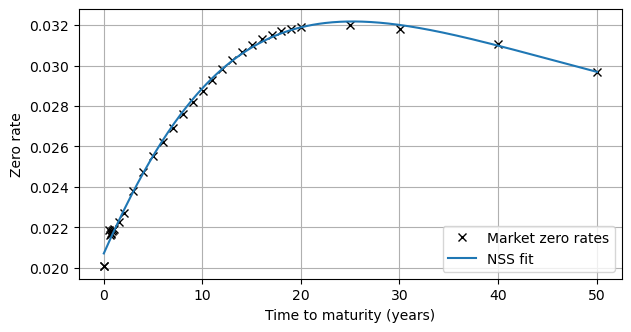

In [9]:
# Plot the NSS curve

plt.figure(figsize=(7, 3.5))
plt.plot(ttm365, z_mkt, "x",color = "black", label="Market zero rates")
plt.plot(tdata, z_fit, "-", label="NSS fit")
plt.xlabel("Time to maturity (years)")
plt.ylabel("Zero rate")
plt.legend()
plt.grid(True)
plt.show()

In [10]:
residuals_bp = (nss_zero_rate(ttm365, b0, b1, b2, b3, tau1, tau2) - z_mkt) * 10000.0

rmse = np.sqrt(np.mean(residuals_bp**2))
max_err = np.max(np.abs(residuals_bp))

print(f"RMSE (bp): {rmse:.2f}")
print(f"Max abs error (bp): {max_err:.2f}")

RMSE (bp): 2.26
Max abs error (bp): 6.54


A 2.26 bp RMSE indicates a good fit of the NSS, meaning high overall precision, the model "tracks" the market well.
Meanwhile the maxi error of 6.54 bps is overall a good indicator of the "worst case scenario", probably influenced by a market outlier.

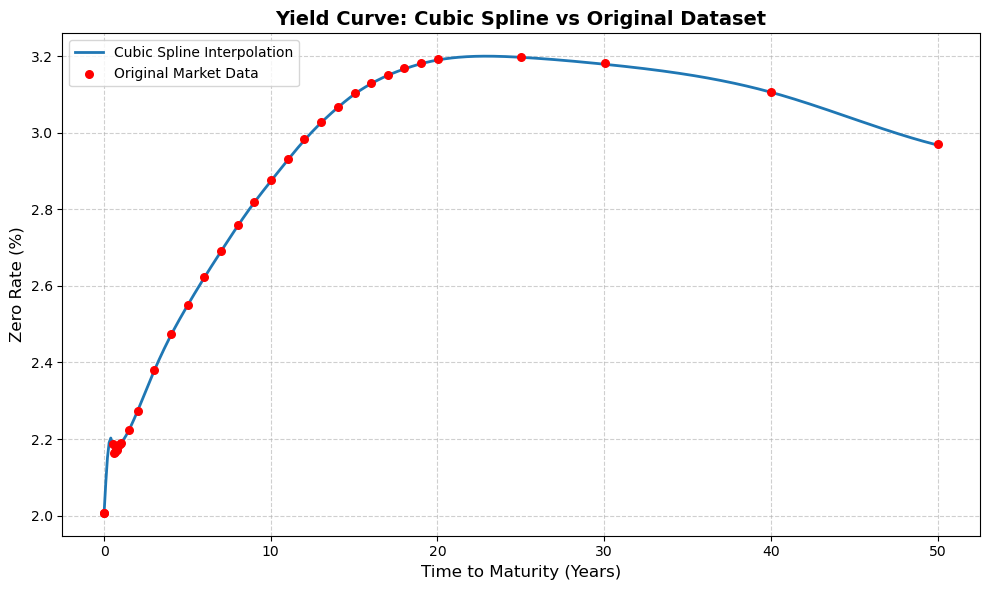

In [43]:
t_mkt = data["TTM365"].to_numpy(float)
z_mkt = data["ZeroRate_pct"].astype(float).to_numpy() 

t_fine = np.linspace(t_mkt.min(), t_mkt.max(), 500)
df_spline = P(t_fine)  

z_spline = -np.log(df_spline) / np.maximum(t_fine, 1e-5)
z_spline_pct = z_spline * 100

plt.figure(figsize=(10, 6))

plt.plot(t_fine, z_spline_pct, label='Cubic Spline Interpolation', color='#1f77b4', linewidth=2)

# Plot the original points
plt.scatter(t_mkt, z_mkt, color='red', marker='o', s=30, label='Original Market Data', zorder=5)

plt.title("Yield Curve: Cubic Spline vs Original Dataset", fontsize=14, fontweight='bold')
plt.xlabel("Time to Maturity (Years)", fontsize=12)
plt.ylabel("Zero Rate (%)", fontsize=12)
plt.legend(loc='best')
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

### Cubic.Spline 

A Cubic Spline is a piecewise polynomial interpolation. Instead of fitting one single complex function to all data points, the model divides the maturity spectrum into segments (intervals between "knots") and fits a third-degree polynomial to each segment. To ensure a smooth curve the result must attain continuity and differentiability conditions.

The Cubic.Spline follows a non-parametric local fit approach, ensuring market consistency by passing through every data point provided, unlike the NSS which provides a parametric "best fit" approach producing residuals.

In our case we prefer the Cubic.Spline yield curve since it provides more precise data for hedging and pricing. While for long-term estimation, where the data given cover just a portion of the estimation period (which is not this case) it is preferable the NSS parametric approach.


# Pricing fixed-income portfolios

First we need to define two new datasets called data_bp_plus1 and data_bp_minus1, accounting for the upward and downward parallel 1 bp shifts of the zero rates, that will be used to compute sentivities. 
With these dataset we compute the new yield curve, to compute the discount factors, derived with the function Cubic.Spline. In contrast with the NSS, Cubic.Spline generates a curve passing from every zero rate point given, providing a more pointwise accurate estiamtion of the yield curve.

The forward rates are compute exploiting the discount factor extracted from the Cubic.Spline curve, that we will denote as P for the standard "6m-zero-curve" dataset, and as P_bp_plus1 and P_bp_minus1 for the 1 bp upward and downward shift respectively, and are calculated as follows:
$$F(t,T_1, T_2) = -\frac{1}{\alpha(T_1, T_2)} \ln\left( \frac{P(t, T_2)}{P(t, T_1)} \right)$$

In [11]:
data_bp_plus1=data.copy() # Define the dataset with 1 bp zero rates up shifted
data_bp_minus1=data.copy() # Define the dataset with 1 bp zero rates down shifted

t = data_bp_plus1["TTM365"].to_numpy(float) # Maturity

data_bp_plus1["ZeroRate_pct_bp"]=data_bp_plus1["ZeroRate_pct"].astype(float) + 0.01
data_bp_minus1["ZeroRate_pct_bp"]=data_bp_minus1["ZeroRate_pct"].astype(float) - 0.01

r_up = (data_bp_plus1["ZeroRate_pct_bp"].to_numpy(float))/100
r_down = (data_bp_minus1["ZeroRate_pct_bp"].to_numpy(float))/100

data_bp_plus1["df_bp"] = np.exp(-r_up*t)
data_bp_plus1 = data_bp_plus1[["Tenor", "EndDate", "TTM365","TTM360", "ZeroRate_pct", "ZeroRate_pct_bp", "df", "df_bp"]].copy()
data_bp_minus1["df_bp"] = np.exp(-r_down*t)
data_bp_minus1 = data_bp_minus1[["Tenor", "EndDate", "TTM365","TTM360", "ZeroRate_pct", "ZeroRate_pct_bp", "df", "df_bp"]].copy()

df_bp_plus1 = data_bp_plus1["df_bp"].to_numpy(float)
P_bp_plus1 = CubicSpline(t, df_bp_plus1, bc_type="natural")
df_bp_minus1 = data_bp_minus1["df_bp"].to_numpy(float)
P_bp_minus1 = CubicSpline(t, df_bp_minus1, bc_type="natural")

data_bp_plus1.head()

,Tenor,EndDate,TTM365,TTM360,ZeroRate_pct,ZeroRate_pct_bp,df,df_bp
2,1D,2025-12-12,0.002740,0.002778,2.007445,2.017445,0.999945,0.999945
3,TN,2025-12-15,0.010959,0.011111,2.007362,2.017362,0.99978,0.999779
4,0X6,2026-06-15,0.509589,0.516667,2.186233,2.196233,0.988921,0.988871
5,1X7,2026-07-15,0.591781,0.600000,2.163646,2.173646,0.987278,0.987219
6,2X8,2026-08-17,0.682192,0.691667,2.165711,2.175711,0.985334,0.985267


## (1) Coupon bond

Maturity: May 12, 2027

Notional: N = 100 €

Coupon rate (annual): C = 3%


The funcrtion generates the cashflow timeline with the given function get_schedule_dataframe, determinating the Pay dates and the Year frac for each period of payment, adopting the ACT/ACT day count. This step will be computed for every instrument depending on their own payment time's characteristics.

For each payment date $T_i$, we calculate the time from settlement (Pay Time) and we extract the relative discount factor from the yield curve. We will use as a yield curve the Cubic.Spline derived curve P.

The cashflows are computed as follows:
$CF_i = N \cdot c \cdot \alpha_(T_{i-1},T_i)$ until the penultimate cashflow, and
$CF_n = (N \cdot c \cdot \alpha_(T_{n-1},T_n) + N$ for the final cashflow, when the notional is redeemed at maturity n.

The dirty price is then computed by summing the discounted cashflows: $$Dirty Price = \sum_{i=1}^{n} CF_i \cdot P(0, T_i)$$

For the accrued interests we calculate the portion of interest earned from the last coupon date $T_{i-1}$ to $t$, which must be compensated to the seller: $$AI = N \cdot c \cdot \alpha(T_{i-1}, t)$$

Finally we obtain the clean price by subtracting the accrued interests from the dirty price:
$$Clean Price = Dirty Price - AI$$

In [12]:
settlement = ql.Date(11,ql.December, 2025)
maturity_date1 = ql.Date(12,ql.May,2027) 

day_rolling = ql.ModifiedFollowing 
calendar = ql.TARGET() 

# Coupon bond data
rate = 0.03
notional = 100
tenor = ql.Period(12,ql.Months) 
day_count = ql.ActualActual(ql.ActualActual.ISDA)

# Compute the coupon schedule
table = get_schedule_dataframe(settlement,
                        maturity_date1,
                        tenor,
                        day_count,
                        calendar,
                        day_rolling,
                        end_of_month=False)

table.index = np.arange(1, len(table) + 1)
table.style

May 12th, 2025


,Start Date,Pay Date,YearFrac,Pay Time
1,"May 12th, 2025","May 12th, 2026",1.000000,0.416438
2,"May 12th, 2026","May 12th, 2027",1.000000,1.416438


In [13]:
t = data["TTM365"].to_numpy(float)
df = data["df"].to_numpy(float)

# sort + unique (CubicSpline vuole t strettamente crescente)
t = t[np.argsort(t)]
df = df[np.argsort(t)]
t, idx = np.unique(t, return_index=True)
df = df[idx]

P = CubicSpline(t, df, bc_type="natural")   # P(t) = DF(t)

In [14]:
# 1) DF ai pay dates (Pay Time in anni)
table["DF"] = P(table["Pay Time"].to_numpy(float))

# 2) Cashflows (fixed coupon)
table["CashFlow"] = notional * rate * table["YearFrac"]
table.loc[table.index.max(), "CashFlow"] += notional  # redemption at maturity

# 3) Dirty price
table["DiscCF"] = table["CashFlow"] * table["DF"]
dirty = float(table["DiscCF"].sum())

# last coupon date = start date dell’ultima accrual period 
last_coupon = table.loc[1, "Start Date"] 

# 4) Accrued interest
AI = notional * rate * day_count.yearFraction(last_coupon, settlement)

clean = dirty - AI

print("Dirty:", dirty)
print("AI:", AI)
print("Clean:", clean)

Dirty: 102.78840772771152
AI: 1.7506849315068496
Clean: 101.03772279620466


#### CB function + DV01 results

In [15]:
def price_coupon_bond(settlement, maturity_date, coupon_rate, notional, tenor, day_count, calendar, day_rolling, P_func):

    # 1) Compute the coupon schedule
    df_bond = get_schedule_dataframe(settlement,
                                     maturity_date,
                                     tenor,
                                     day_count,
                                     calendar,
                                     day_rolling,
                                     end_of_month=False)
    df_bond
    # 2) Compute Pay Times and Discount Factors
    df_bond["Pay Time"] = np.array([float(d - settlement)/365.0 for d in df_bond["Pay Date"]], dtype=float)
    df_bond["DF"] = P_func(df_bond["Pay Time"].to_numpy(float))
    
    # 3) Compute the Cash Flows
    df_bond["CashFlow"] = notional * coupon_rate * df_bond["YearFrac"]
    df_bond.loc[df_bond.index.max(), "CashFlow"] += notional
    
    # 4) Dirty Price
    df_bond["DiscCF"] = df_bond["CashFlow"] * df_bond["DF"]
    dirty_price = float(df_bond["DiscCF"].sum())
    
    # 5) Accrued Interest
    last_coupon = df_bond.iloc[0]["Start Date"] 
    # Usiamo il day counter specifico (nel tuo codice per il bond 1 è ActualActual ISDA)
    day_count = ql.ActualActual(ql.ActualActual.ISDA)
    
    # AI = Notional * Rate * YearFrac
    accrued_interest = notional * coupon_rate * day_count.yearFraction(last_coupon, settlement)
    
    # 6) Clean Price
    clean_price = dirty_price - accrued_interest
    
    return {
        "dirty_price": dirty_price,
        "clean_price": clean_price,
        "accrued_interest": accrued_interest,
        "table": df_bond
    }

In [16]:
# Coupon Bond Pricing
cb = price_coupon_bond(settlement, maturity_date = ql.Date(12,5,2027), coupon_rate = 0.03, notional = 100,
                  tenor = ql.Period(12, ql.Months), day_count = ql.ActualActual(ql.ActualActual.ISDA), calendar = ql.TARGET(),
                  day_rolling = ql.ModifiedFollowing, P_func = P)
# Coupon Bond sensitivity to a 1 bp zero rate up shift
cb_plus1 = price_coupon_bond(settlement, maturity_date = ql.Date(12,5,2027), coupon_rate = 0.03, notional = 100,
                  tenor = ql.Period(12, ql.Months), day_count = ql.ActualActual(ql.ActualActual.ISDA), calendar = ql.TARGET(),
                  day_rolling = ql.ModifiedFollowing, P_func = P_bp_plus1)
# Coupon Bond sensitivity to a 1 bp zero rate down shift
cb_minus1 = price_coupon_bond(settlement, maturity_date = ql.Date(12,5,2027), coupon_rate = 0.03, notional = 100,
                  tenor = ql.Period(12, ql.Months), day_count = ql.ActualActual(ql.ActualActual.ISDA), calendar = ql.TARGET(),
                  day_rolling = ql.ModifiedFollowing, P_func = P_bp_minus1)

print("CB base   =", cb["clean_price"])
print("CB +1bp   =", cb_plus1["clean_price"])
print("CB -1bp   =", cb_minus1["clean_price"])

print("(+1bp)-base =", cb_plus1["clean_price"] - cb["clean_price"])
print("(-1bp)-base =", cb_minus1["clean_price"] - cb["clean_price"])

cb_dv01 = (cb_minus1['clean_price']-cb_plus1['clean_price'])/2
print("CB DV01   =", cb_dv01)

May 12th, 2025
May 12th, 2025
May 12th, 2025
CB base   = 101.03772279620466
CB +1bp   = 101.02341982635953
CB -1bp   = 101.05194394354214
(+1bp)-base = -0.014302969845132907
(-1bp)-base = 0.014221147337480033
CB DV01   = 0.01426205859130647


### CB DV01 Interpretation

DV01 represents the change in the price of a financial instrument (or a whole portfolio) resulting from a one basis point (0.01%) parallel shift in the yield curve.
It measures in "Euros" the price sensitivity, pointing out exactly how much money you gain or lose for every 1 basis point shift in the yield curve.

$$\frac{\partial V}{\partial \beta}(\beta_0) \approx \frac{V(\beta_0 - \epsilon) - V(\beta_0 + \epsilon)}{2\epsilon}$$

Here $\beta_0$ represents the initial zero rate vector, and $\epsilon$ is the shift appliet do the yield curve. In uor case, we manually shifted the zero rate curve, as shown in the data sets data_bp_plus1 and data_bp_minus1, and then we computed the yield curve exploiting Cubic.Spline interpolation, however, similar results are obtainable by inputting the shift into the NSS to compute the new discount factors and forward rates.

DV01 can be interpreted as the loss following a 1 bp yield curve shift, therefore, a negative DV01 implies a negative loss (a gain) in the event of a 1 bp upward yield curve shift and a positive loss in the event of a 1 bp dowward shift.

Coupon bond's DV01 is equal to 0.01426205859130647, indicating a change in price in the inverse direction of the yield curve shift.

## (2) FRN

Notional: EUR €

Maturity: June 18, 2027

Coupon (monthly): 1m Euribor + 200 bps

Current coupon: 2.13%

First we generate again the cashflow timeline with the function get_schedule_dataframe.
Then, to estimate future unknown coupons , after the first period 2.13% fixed coupon,  we calculate the continuously compounded forward rates ($F(t,T_i, T_{i+1})$) for future periods. First, we obtain the discount factors ($DF$) from the yield curve function (P), and then we compute the forward rates  
$$F(t,T_i, T_{i+1}) = -\frac{1}{\alpha(T_i, T_{i+1})} \ln\left( \frac{P(t, T_{i+1})}{P(t, T_i)} \right)$$
Knowing the forward rates we can express the future coupon rates as:
$C_i = Fwd_i + Spread$ 

Finally, we can compute the cashflows: $CF_i = N \cdot Rate_i \cdot \alpha_i$ until the penultimate period, and then $CF_n = (N \cdot Rate_n \cdot \alpha_n) + N$ for the last period n. 

The dirty price, accrued interest and clean price are computed as for coupon bond

In [17]:
maturity_date2 = ql.Date(18,ql.June,2027) 

# Coupon bond data
rate = 0.0213
notional = 100
tenor = ql.Period(1,ql.Months) 
day_count = ql.Actual360()

# Compute the coupon schedule
table = get_schedule_dataframe(settlement,
                        maturity_date2,
                        tenor,
                        day_count,
                        calendar,
                        day_rolling,
                        end_of_month=False)

table.index = np.arange(1, len(table) + 1)
table

November 18th, 2025


,Start Date,Pay Date,YearFrac,Pay Time
1,"November 18th, 2025","December 18th, 2025",0.083333,0.019178
2,"December 18th, 2025","January 19th, 2026",0.088889,0.106849
3,"January 19th, 2026","February 18th, 2026",0.083333,0.189041
4,"February 18th, 2026","March 18th, 2026",0.077778,0.265753
5,"March 18th, 2026","April 20th, 2026",0.091667,0.356164
6,"April 20th, 2026","May 18th, 2026",0.077778,0.432877
7,"May 18th, 2026","June 18th, 2026",0.086111,0.517808
8,"June 18th, 2026","July 20th, 2026",0.088889,0.605479
9,"July 20th, 2026","August 18th, 2026",0.080556,0.684932
10,"August 18th, 2026","September 18th, 2026",0.086111,0.769863


In [18]:
spread = 0.02
current_coupon = 0.0213
notional = 100.0

# DF ai Pay Date (end)
table["DF_end"] = P(table["Pay Time"].to_numpy(float))

t_start = np.array([float(d - settlement)/365.0 for d in table["Start Date"]], dtype=float)
t_start = np.maximum(t_start, 0.0)

table["DF_start"] = P(t_start)

# Continuously compounded froward rate are used to avoid arbitrage when we will use the Hull-White calibration
table["Fwd Rate"] = -np.log(table["DF_end"] / table["DF_start"]) / table["YearFrac"]

# First coupon is fixed
table["Spread"] = spread
table["Coupon Rate"] = table["Fwd Rate"] + spread
table.loc[1, "Coupon Rate"] = current_coupon

# cashflows
table["Cash Flow"] = notional * table["Coupon Rate"] * table["YearFrac"]
table.loc[table.index.max(), "Cash Flow"] += notional

table["Disc. Cash Flow"] = table["Cash Flow"] * table["DF_end"]
dirty_frn = float(table["Disc. Cash Flow"].sum())

last_coupon = table.loc[1, "Start Date"]
coupon_payment = table.loc[1, "Pay Date"]

alpha_accrued = day_count.yearFraction(last_coupon, settlement)
AI = notional * current_coupon * alpha_accrued

clean_frn = dirty_frn - AI

print("FRN Dirty:", dirty_frn)
print("Accrued (AI):", AI)
print("FRN Clean:", clean_frn)


FRN Dirty: 103.12120650676165
Accrued (AI): 0.1360833333333333
FRN Clean: 102.98512317342832


#### FRN'S function + DV01 results

In [19]:
def price_frn(settlement, maturity_date, spread, current_coupon, notional, tenor, day_count, calendar, day_rolling, P_func):
    """
    Calcola Dirty Price, Accrued Interest e Clean Price per un FRN (Floating Rate Note).
    """
    # Generazione dello schedule
    df_frn = get_schedule_dataframe(settlement,
                                    maturity_date,
                                    tenor,
                                    day_count,
                                    calendar,
                                    day_rolling,
                                    end_of_month=False)
    df_frn.index = np.arange(1, len(df_frn) + 1)
    
    # Compute Pay Times and Discount Factors
    df_frn["Pay Time"] = np.array([float(d - settlement)/365.0 for d in df_frn["Pay Date"]], dtype=float)
    df_frn["DF_end"] = P_func(df_frn["Pay Time"].to_numpy(float))
    
    t_start = np.array([float(d - settlement)/365.0 for d in df_frn["Start Date"]], dtype=float)
    t_start = np.maximum(t_start, 0.0)
    df_frn["DF_start"] = P_func(t_start)
    
    # Continuously compounded forward rate
    df_frn["Fwd Rate"] = -np.log(df_frn["DF_end"] / df_frn["DF_start"]) / df_frn["YearFrac"]

    # First coupon is fixed
    df_frn["Coupon Rate"] = df_frn["Fwd Rate"] + spread
    df_frn.loc[1, "Coupon Rate"] = current_coupon
    
    # Compute Cashflows and dirty price
    df_frn["CashFlow"] = notional * df_frn["Coupon Rate"] * df_frn["YearFrac"]
   
    df_frn.loc[df_frn.index.max(), "CashFlow"] += notional
    
    # Sconto dei flussi
    df_frn["DiscCF"] = df_frn["CashFlow"] * df_frn["DF_end"]
    dirty_price = float(df_frn["DiscCF"].sum())
    
    # Accrued Interest (AI)
    day_count_accrued = ql.Actual360() 
    start = df_frn.loc[1, "Start Date"]
    alpha_accrued = day_count_accrued.yearFraction(start, settlement)
    accrued_interest = notional * current_coupon * alpha_accrued
    
    # 6. Clean Price
    clean_price = dirty_price - accrued_interest
    
    return {
        "dirty_price": dirty_price,
        "clean_price": clean_price,
        "accrued_interest": accrued_interest,
        "table": df_frn
    }

In [20]:
# FRN pricing
frn = price_frn(settlement, maturity_date=maturity_date2, spread=0.02, current_coupon=0.0213,
    notional=100.0, tenor=ql.Period(1, ql.Months), day_count=ql.Actual360(), calendar=ql.TARGET(), day_rolling=ql.ModifiedFollowing,
    P_func=P)

# FRN sensitivity to a 1 bp zero rate up shift
frn_plus1 = price_frn(settlement, maturity_date=maturity_date2, spread=0.02, current_coupon=0.0213,
    notional=100.0, tenor=ql.Period(1, ql.Months), day_count=ql.Actual360(), calendar=ql.TARGET(), day_rolling=ql.ModifiedFollowing,
    P_func=P_bp_plus1)

# FRN sensitivity to a 1 bp zero rate down shift
frn_minus1 = price_frn(settlement, maturity_date=maturity_date2, spread=0.02, current_coupon=0.0213,
    notional=100.0, tenor=ql.Period(1, ql.Months), day_count=ql.Actual360(), calendar=ql.TARGET(), day_rolling=ql.ModifiedFollowing,
    P_func=P_bp_minus1)



print("FRN base   =", frn["clean_price"])
print("FRN +1bp   =", frn_plus1["clean_price"])
print("FRN -1bp   =", frn_minus1["clean_price"])

print("\n(+1bp) - base =", frn_plus1["clean_price"] - frn["clean_price"] )
print("(-1bp) - base =", frn_minus1["clean_price"] - frn["clean_price"] )
frn_dv01 = (frn_minus1['clean_price']-frn_plus1['clean_price'])/2
print("FRN DV01   =", frn_dv01)

November 18th, 2025
November 18th, 2025
November 18th, 2025
FRN base   = 102.98512317342832
FRN +1bp   = 102.984663034655
FRN -1bp   = 102.98558268756001

(+1bp) - base = -0.0004601387733202955
(-1bp) - base = 0.0004595141316912077
FRN DV01   = 0.0004598264525057516


### FRN DV01 interpretation

The DV01 for the FRN, indicates an inverse relationship between interest rate growth and FRN's price. This relationship is due to the decrease in value of the floating leg, while the fixed leg remains constant despite interest rate changes. 

FRN's DV01 equals to 0.0004598264525057516, which is a very low sensitivity index, meaning that the price will change by just 0.00046€ for a 100€ notional, in the opposite direction of the rate change, and so the risk implied by this instrument is very small.

The low differrence between the reactions of the FRN to a 1 bp upward and downward shift of the yield curve highligts an almost zero convexity of the instrument.

### (3) INTEREST RATE SWAP

Maturity: October 10, 2028

Notional: N = 100,000 €

Fixed rate (annual): R = 2%

Current floating coupon = 0.34%

Floating leg (semi-annual) = 6m Euribor 

We adopt the ACT/ACT daycount for the fixed leg and the ACT/360 daycount for the floating leg.

To evaluate the value of the Interest Rate Swap we compute the difference between the present value of the fixed leg and the floating leg.

Fixed leg:
The fixed leg consists of a stream of pre-determined payments, whose cashflows are computed as follows: $$CF_{1} = N \cdot R \cdot \alpha({t, T_{1}})$$
Then the clear price is computed by subtracting the accrued interest to the dirty price.

Floating Leg:
After computing the forward rates with the continuously compounding regime we calculate the first coupon with the current floating rate. After the first coupon we recursively compute the coupons as follows: $CF_i = N \cdot F(t,T_i, T_{i+1}) \cdot \alpha({T_i, T_{i+1}})$
and we derive the clean price for the floating leg as usual:
$$Dirty Price = \sum_{i=1}^{n} CF_i \cdot P(0, T_i)$$
$$AI = N \cdot c \cdot \alpha(T_{i-1}, t)$$
$$Clean Price = Dirty Price - AI$$

Finally we compute the NPV of the IRS, which is equal to the difference between the floating leg (what we receive) and the fixed leg (what we pay): $NPV_{IRS}= PV_{float} - PV_{fixed}$

In [21]:
maturity_date3 = ql.Date(10,ql.October,2028) 

tenor_fixed = ql.Period(12,ql.Months) 
tenor_float = ql.Period(6,ql.Months) 
day_count_fixed = ql.ActualActual(ql.ActualActual.ISDA)
day_count_float = ql.Actual360()

# Compute the coupon schedule
table_fixed = get_schedule_dataframe(settlement,
                        maturity_date3,
                        tenor_fixed,
                        day_count_fixed,
                        calendar,
                        day_rolling,
                        end_of_month=False)

table_float = get_schedule_dataframe(settlement,
                        maturity_date3,
                        tenor_float,
                        day_count_float,
                        calendar,
                        day_rolling,
                        end_of_month=False)

table_fixed.index = np.arange(1, len(table_fixed) + 1)
table_float.index = np.arange(1, len(table_float) + 1)

table_fixed[["Start Date","Pay Date","YearFrac","Pay Time"]]

October 10th, 2025
October 10th, 2025


,Start Date,Pay Date,YearFrac,Pay Time
1,"October 10th, 2025","October 12th, 2026",1.005479,0.835616
2,"October 12th, 2026","October 11th, 2027",0.997260,1.832877
3,"October 11th, 2027","October 10th, 2028",0.997882,2.830758


In [22]:
table_float[["Start Date","Pay Date","YearFrac","Pay Time"]]

,Start Date,Pay Date,YearFrac,Pay Time
1,"October 10th, 2025","April 10th, 2026",0.505556,0.328767
2,"April 10th, 2026","October 12th, 2026",0.513889,0.835616
3,"October 12th, 2026","April 12th, 2027",0.505556,1.334247
4,"April 12th, 2027","October 11th, 2027",0.505556,1.832877
5,"October 11th, 2027","April 10th, 2028",0.505556,2.330758
6,"April 10th, 2028","October 10th, 2028",0.508333,2.830758


In [23]:
# t_start e t_end in anni 
t_start = np.array([float(d - settlement)/360.0 for d in table_float["Start Date"]], dtype=float)
t_end   = np.array([float(d - settlement)/360.0 for d in table_float["Pay Date"]],   dtype=float)

t_start = np.maximum(t_start, 0.0)

# DF start/end dalla Spline
table_float["DF_start"] = P(t_start)
table_float["DF_end"]   = P(t_end)

# Continuously compounded Discount Factor
table_float["Fwd Euribor"] = -np.log(table_float["DF_end"] / table_float["DF_start"]) / table_float["YearFrac"]

table_float[["Start Date","Pay Date","YearFrac", "Pay Time", "DF_start","DF_end","Fwd Euribor"]]

,Start Date,Pay Date,YearFrac,Pay Time,DF_start,DF_end,Fwd Euribor
1,"October 10th, 2025","April 10th, 2026",0.505556,0.328767,1.000000,0.992703,0.014486
2,"April 10th, 2026","October 12th, 2026",0.513889,0.835616,0.992703,0.981672,0.021745
3,"October 12th, 2026","April 12th, 2027",0.505556,1.334247,0.981672,0.970521,0.022596
4,"April 12th, 2027","October 11th, 2027",0.505556,1.832877,0.970521,0.958910,0.023808
5,"October 11th, 2027","April 10th, 2028",0.505556,2.330758,0.958910,0.946838,0.025060
6,"April 10th, 2028","October 10th, 2028",0.508333,2.830758,0.946838,0.934335,0.026150


In [24]:
# Compute Pay Times and Discount Factors
t_pay_fix = np.array([float(d - settlement)/365.25 for d in table_fixed["Pay Date"]], dtype=float)
table_fixed["Pay Time"] = t_pay_fix 
table_fixed["DF fix"] = P(table_fixed["Pay Time"].to_numpy(float))

table_fixed[["Start Date","Pay Date","YearFrac","Pay Time","DF fix"]].head()

,Start Date,Pay Date,YearFrac,Pay Time,DF fix
1,"October 10th, 2025","October 12th, 2026",1.005479,0.835044,0.981943
2,"October 12th, 2026","October 11th, 2027",0.997260,1.831622,0.959535
3,"October 11th, 2027","October 10th, 2028",0.997882,2.830938,0.935360


In [25]:
notional_frn = 100000
rate_fixed = 0.02

# cashflow fisso: N * K * alpha
table_fixed["CF_fix"] = notional_frn * rate_fixed * table_fixed["YearFrac"]

# PV cashflow
table_fixed["PV_fix"] = table_fixed["CF_fix"] * table_fixed["DF fix"]

PV_fixed = float(table_fixed["PV_fix"].sum())

# Fixed Leg
print("PV fixed leg =", PV_fixed)
table_fixed[["Start Date","Pay Date","YearFrac","Pay Time","DF fix","CF_fix","PV_fix"]]

start_fix = table_fixed.loc[1, "Start Date"]

alpha_accrued_fix = day_count_fixed.yearFraction(start_fix, settlement)
AI_fix = notional_frn * rate_fixed * alpha_accrued_fix

PV_fixed_clean = PV_fixed - AI_fix

print("Accrued fixed (AI) =", AI_fix)
print("PV fixed clean =", PV_fixed_clean)

PV fixed leg = 5755.216244907011
Accrued fixed (AI) = 339.72602739726045
PV fixed clean = 5415.49021750975


In [26]:
current_float = 0.0034
table_float["CouponRate_flt"] = table_float["Fwd Euribor"]
table_float.loc[1, "CouponRate_flt"] = current_float

# cashflow e PV cashflow
table_float["CF_flt"] = notional_frn * table_float["CouponRate_flt"] * table_float["YearFrac"]
table_float["PV_flt"] = table_float["CF_flt"] * table_float["DF_end"]

PV_float = float(table_float["PV_flt"].sum())

start_flt = table_float.loc[1, "Start Date"] 
alpha_accrued_flt = day_count_float.yearFraction(start_flt, settlement)

AI_float = notional_frn * current_float * alpha_accrued_flt

PV_float_clean = PV_float - AI_float

print("alpha_accrued_flt =", alpha_accrued_flt)
print("PV float leg (dirty) =", PV_float)
print("Accrued float (AI) =", AI_float)
print("PV float clean =", PV_float_clean)



table_float[["Start Date","Pay Date","YearFrac","CouponRate_flt","CF_flt","DF_end","PV_flt"]]

alpha_accrued_flt = 0.17222222222222222
PV float leg (dirty) = 5972.083658960001
Accrued float (AI) = 58.55555555555556
PV float clean = 5913.528103404446


,Start Date,Pay Date,YearFrac,CouponRate_flt,CF_flt,DF_end,PV_flt
1,"October 10th, 2025","April 10th, 2026",0.505556,0.003400,171.888889,0.992703,170.634661
2,"April 10th, 2026","October 12th, 2026",0.513889,0.021745,1117.470294,0.981672,1096.989133
3,"October 12th, 2026","April 12th, 2027",0.505556,0.022596,1142.371270,0.970521,1108.695679
4,"April 12th, 2027","October 11th, 2027",0.505556,0.023808,1203.648052,0.958910,1154.189776
5,"October 11th, 2027","April 10th, 2028",0.505556,0.025060,1266.927215,0.946838,1199.574364
6,"April 10th, 2028","October 10th, 2028",0.508333,0.026150,1329.288130,0.934335,1242.000047


In [27]:
PV_float_clean - PV_fixed_clean

498.03788589469514

#### IRS function + DV01 RESULTS

In [28]:
def price_irs(settlement, maturity_date, rate_fixed, current_float, notional, 
                   tenor_fixed, tenor_float, 
                   day_count_fixed, day_count_float, 
                   calendar, day_rolling, P_func):
   
    
    # Fixed Leg
    df_fixed = get_schedule_dataframe(settlement, maturity_date, tenor_fixed, 
                                      day_count_fixed, calendar, day_rolling, False)
    df_fixed.index = np.arange(1, len(df_fixed) + 1)

    df_fixed["Pay Time"] = np.array([float(d - settlement)/365.0 for d in df_fixed["Pay Date"]], dtype=float)
    df_fixed["DF"] = P_func(df_fixed["Pay Time"].to_numpy(float))
    
    df_fixed["CF_fix"] = notional * rate_fixed * df_fixed["YearFrac"]
    df_fixed["PV_fix"] = df_fixed["CF_fix"] * df_fixed["DF"]
    pv_fixed_dirty = float(df_fixed["PV_fix"].sum())
    
    # Accrued Fixed
    start_fix = df_fixed.loc[1, "Start Date"]
    ai_fixed = notional * rate_fixed * day_count_fixed.yearFraction(start_fix, settlement)
    pv_fixed_clean = pv_fixed_dirty - ai_fixed

    # 2) Floating Leg
    df_float = get_schedule_dataframe(settlement, maturity_date, tenor_float, 
                                      day_count_float, calendar, day_rolling, False)
    df_float.index = np.arange(1, len(df_float) + 1)

    t_start_flt = np.array([float(d - settlement)/365.0 for d in df_float["Start Date"]], dtype=float)
    t_end_flt = np.array([float(d - settlement)/365.0 for d in df_float["Pay Date"]], dtype=float)
    t_start_flt = np.maximum(t_start_flt, 0.0)
    
    df_float["DF_start"] = P_func(t_start_flt)
    df_float["DF_end"] = P_func(t_end_flt)
    
    # Continuously compounded forward Rates
    df_float["Fwd Euribor"] = -np.log(df_float["DF_end"] / df_float["DF_start"]) / df_float["YearFrac"]
    df_float["CouponRate_flt"] = df_float["Fwd Euribor"]
    df_float.loc[1, "CouponRate_flt"] = current_float
    
    df_float["CF_flt"] = notional * df_float["CouponRate_flt"] * df_float["YearFrac"]
    df_float["PV_flt"] = df_float["CF_flt"] * df_float["DF_end"]
    pv_float_dirty = float(df_float["PV_flt"].sum())
    
    # Accrued Float
    start_flt = df_float.loc[1, "Start Date"]
    ai_float = notional * current_float * day_count_float.yearFraction(start_flt, settlement)
    pv_float_clean = pv_float_dirty - ai_float

    npv_irs = pv_float_clean - pv_fixed_clean
    
    return {
        "npv_irs": npv_irs,
        "pv_fixed_clean": pv_fixed_clean,
        "pv_float_clean": pv_float_clean,
        "ai_fixed": ai_fixed,
        "ai_float": ai_float,
        "table_fixed": df_fixed,
        "table_float": df_float
    }


In [29]:
# IRS pricing
irs = price_irs(settlement, maturity_date=maturity_date3, rate_fixed=0.02, current_float=0.0034,
    notional=notional_frn, tenor_fixed=ql.Period(12, ql.Months), tenor_float=ql.Period(6, ql.Months), day_count_fixed=ql.ActualActual(ql.ActualActual.ISDA),
    day_count_float=ql.Actual360(), calendar=ql.TARGET(), day_rolling=ql.ModifiedFollowing, P_func=P)

# IRS sensitivity to a 1 bp zero rate up shift
irs_plus1 = price_irs(settlement, maturity_date=maturity_date3, rate_fixed=0.02, current_float=0.0034,
    notional=notional_frn, tenor_fixed=ql.Period(12, ql.Months), tenor_float=ql.Period(6, ql.Months), day_count_fixed=ql.ActualActual(ql.ActualActual.ISDA),
    day_count_float=ql.Actual360(), calendar=ql.TARGET(), day_rolling=ql.ModifiedFollowing, P_func=P_bp_plus1)

# IRS sensitivity to a 1 bp zero rate down shift
irs_minus1 = price_irs(settlement, maturity_date=maturity_date3, rate_fixed=0.02, current_float=0.0034,
    notional=notional_frn, tenor_fixed=ql.Period(12, ql.Months), tenor_float=ql.Period(6, ql.Months), day_count_fixed=ql.ActualActual(ql.ActualActual.ISDA),
    day_count_float=ql.Actual360(), calendar=ql.TARGET(), day_rolling=ql.ModifiedFollowing, P_func=P_bp_minus1)


print(f"NPV IRS (Float Clean - Fixed Clean) base: {irs['npv_irs']:.4f}")
print(f"NPV IRS (Float Clean - Fixed Clean) +1bp : {irs_plus1['npv_irs']:.4f}")
print(f"NPV IRS (Float Clean - Fixed Clean) -1bp : {irs_minus1['npv_irs']:.4f}")
print("DVO1 IRS1 - IRS0", irs_plus1['npv_irs'] - irs['npv_irs'] )
print("DVO1 IRS2 - IRS0",irs_minus1['npv_irs'] - irs['npv_irs'] )

irs_dv01 = (irs_minus1['npv_irs']-irs_plus1['npv_irs'])/2
print("FRN DV01   =", irs_dv01)

October 10th, 2025
October 10th, 2025
October 10th, 2025
October 10th, 2025
October 10th, 2025
October 10th, 2025
NPV IRS (Float Clean - Fixed Clean) base: 411.7934
NPV IRS (Float Clean - Fixed Clean) +1bp : 440.9242
NPV IRS (Float Clean - Fixed Clean) -1bp : 392.9471
DVO1 IRS1 - IRS0 29.130724460062993
DVO1 IRS2 - IRS0 -18.84632160426736
FRN DV01   = -23.988523032165176


## IRS DV01 interpretation

For IRS DV01 is equal to -23.988523032165176, therefore, IRS's price will react to 1 bp rate change in the same direction of the change, with a much larger magnitude than coupon bond and FRN, thus, a consistent portion of portfolio rate risk is carried by this instrument. Therefore, we expect to have a negative loss of -23.98€ for a 1 bp increase in interest rates, i.e a 23.98€ price increase for a 1 bp upward shift of the yield curve.

The significant difference between the reaction to an upward and a downward shift in zero rates indicates a large convexity for the IRS.

## ATM Semi-annual cap

An Interest Rate Cap is a portfolio of European options known as Caplets. 
Each Caplet protects the holder against interest rate rises above a specified 
strike $K$.

We employ the Bachelier Model (also known as the Normal Model) because market 
volatilities for caps are typically quoted in Basis Points (Normal Volatility). 

The value of each individual $i$-th Caplet is calculated as:
$$V_{caplet,i} = N \cdot \alpha(T_i,T_{i+1}) \cdot P(0, T_{i}) \cdot \left[ (F_i - K)\Phi(d_i) + \sigma_N\sqrt{\tau}\phi(d_i) \right]$$

Where:
$d_i = \frac{F_i - K}{\sigma_N\sqrt{T_{reset,i}}}$, $\Phi(\cdot)$ and $\phi(\cdot)$ are the standard normal CDF and PDF, respectively, $\alpha$ is the reset time for caplet i, $F_i$ is the forward rate for the period $[T_{i}, T_{i+1}]$, $P(0, T_{payment,i})$ is the discount factor to the payment date, $alpha$ is the year fraction between payment dates (0.5 for semi-annual caplets) and $N$ is the notional amount and $\tau$ is the reset time.

The total Cap price is the sum of all individual caplets:
$$V_{cap} = \sum_{i=0}^{n} V_{caplet,i}$$



In [31]:
cap_quotes = pd.read_excel(
    "data/InputData2025.xlsx",
    sheet_name="cap-vol",
    header=9,
    usecols=["Tenor", "Strike %", "Volatility bp"]
).dropna()

row_4y = cap_quotes.loc[cap_quotes["Tenor"].eq("4Y")]
cap_quotes["Tenor"] = cap_quotes["Tenor"].astype(str).str.strip().str.upper()

strike = float(row_4y.iloc[0]["Strike %"]) / 100.0          # % -> decimale
sigma_N   = float(row_4y.iloc[0]["Volatility bp"]) / 10000.0   # bp -> decimale

notional_cap = 10000
maturity_date4 = ql.Date(11,ql.December,2029) 


In [32]:
def price_cap(P_used, settlement, maturity_date, notional_cap, strike, sigma_N,
                      calendar, day_rolling, time_basis=365):
    tenor_cap = ql.Period(6, ql.Months)
    dc_cap = ql.Actual360()

    table_cap = get_schedule_dataframe(
        settlement,
        maturity_date,
        tenor_cap,
        dc_cap,
        calendar,
        day_rolling,
        end_of_month=False
    ).copy()
    table_cap.index = np.arange(1, len(table_cap) + 1)

    denom = float(time_basis)

    t_start = np.array([max(float(d - settlement)/denom, 0.0) for d in table_cap["Start Date"]], float)
    t_end   = np.array([float(d - settlement)/denom for d in table_cap["Pay Date"]], float)

    table_cap["DF_start"] = P_used(t_start)
    table_cap["DF_end"]   = P_used(t_end)

    table_cap["Fwd"] = -np.log(table_cap["DF_end"]/table_cap["DF_start"]) / table_cap["YearFrac"]

    def phi(x): return exp(-0.5*x*x) / sqrt(2*pi)
    def Phi(x): return 0.5 * (1.0 + erf(x / sqrt(2.0)))

    def bachelier_call(F, K, sigmaN, tau):
        if tau <= 0.0 or sigmaN <= 0.0:
            return max(F - K, 0.0)
        s = sigmaN * sqrt(tau)
        d = (F - K) / s
        return (F - K) * Phi(d) + s * phi(d)

    table_cap["tau"] = t_start

    table_cap["CapletPV"] = [
        float(notional_cap) * float(DF) * float(alpha) * bachelier_call(float(F), float(strike), float(sigma_N), float(tau))
        for DF, alpha, F, tau in zip(table_cap["DF_end"], table_cap["YearFrac"], table_cap["Fwd"], table_cap["tau"])
    ]

    cap_pv = float(np.sum(table_cap["CapletPV"]))
    return cap_pv, table_cap

In [35]:
# ATM Cap pricing
cap , tab0= price_cap(P, settlement, maturity_date4, 10000, strike, sigma_N, calendar, day_rolling, time_basis=365)

# ATM Cap sensitivity to a 1 bp zero rate up shift
cap_plus1, tab1 = price_cap(P_bp_plus1, settlement, maturity_date4, 10000, strike, sigma_N, calendar, day_rolling, time_basis=365)

# ATM Cap sensitivity to a 1 bp zero rate down shift
cap_minus1, tab2 = price_cap(P_bp_minus1, settlement, maturity_date4, 10000, strike, sigma_N, calendar, day_rolling, time_basis=365)

print("Cap PV base =", cap)
print("Cap PV bp +1  =", cap_plus1)
print("Cap PV bp -1 =", cap_minus1)
print("+1 bp change =", cap_plus1 - cap)
print("+1 bp change =", cap_minus1 - cap)

cap_dv01 = (cap_minus1-cap_plus1)/2
print("FRN DV01   =", cap_dv01)

December 11th, 2025
December 11th, 2025
December 11th, 2025
Cap PV base = 107.9374278997844
Cap PV bp +1  = 109.76680667073822
Cap PV bp -1 = 106.79196862750496
+1 bp change = 1.8293787709538236
+1 bp change = -1.1454592722794388
FRN DV01   = -1.4874190216166312


### ATM Semi-annual cap DV01 Interpretation

DV01 equals to DV01 equals to -1.4874190216166312, therefore we expect a negative loss if the interest rates rise by 1 bp.

## Delta Hedge

In the context of fixed incom, delta hedging refers to the sensitivity of portfolio value to changes in interest rates. The goal of a delta hedged portfolio is achieving immunization to small parallel shifts in the yield curve. 

To obtain a delta hedged portfolio we need to introduce a hedging instrument $H$ with a quantity $q$, in order to make the porfolio, still vulnerable to yield curve's parallel shifts, delta hedged.

Introducing a hedging instrument $H$ with a quantity $q$, to the current portfolio P, the value of the hedged portfolio $P_H$ is:$$P_H(y) = P(y) + q \cdot H(y)$$

To achieve an hedged portfolio we need to choose a $q$ quantity, called "hedge_notional" in the code, such that the derivative of this total value with respect to the interest rate $y$ is zero:$$\frac{dP_H}{dy} = 0$$

In [38]:
# 1) Portfolio NPV
total_npv_clean = (
    cb["clean_price"] + 
    frn["clean_price"] + 
    irs["npv_irs"] + 
    cap
)

# 2) DV01 UP 

v01_up_total = (
    (cb_plus1["clean_price"] - cb["clean_price"]) +
    (frn_plus1["clean_price"] - frn["clean_price"]) +
    (irs_plus1["npv_irs"] - irs["npv_irs"]) +
    (cap_plus1 - cap)
)

# 3) DV01 DOWN
v01_down_total = (
    (cb_minus1["clean_price"] - cb["clean_price"]) +
    (frn_minus1["clean_price"] - frn["clean_price"]) +
    (irs_minus1["npv_irs"] - irs["npv_irs"]) +
    (cap_minus1 - cap)
)

print(f"NPV Clean Portafoglio:         {total_npv_clean:.4f}")
print(f"Change +1 bp:        {v01_up_total:.4f}")   # Dovrebbe essere circa +31.35
print(f"Change -1 bp:      {v01_down_total:.4f}") # Dovrebbe essere circa -20.25 (asimmetrico)

ptf_dv01 = (v01_down_total-v01_up_total)/2
print(f"DV01 Totale :      {ptf_dv01}") 

NPV Clean Portafoglio:         723.7537
Change +1 bp:        30.9453
Change -1 bp:      -19.9771
DV01 Totale :      -25.461220168737995


## Hedging instrument

To obtain an hedged portfolio we exploit an IRS, specifically, as we saw previously, IRS's DV01 moves in the same direction of yield curve small shifts (1 bp increase in interest rates increases IRS's price), therefore shorting an IRS with the same maturity, fixed coupon rate and payment dates, floating start coupon rate and payment dates and day count conventions, provides delta hedge.

It is necessary now to calibrate the notional $q$ to achieve delta hedging. 
By setting the derivative of the hedged portfolio to zero, we derive the hedge ratio formula:$$\frac{dP}{dy} + q \frac{dH}{dy} = 0 \implies q = -\frac{P'(y)}{H'(y)}$$
Therefore: $$q = - \frac{DV01_{\text{Portfolio}}}{DV01_{\text{Hedge Instrument}}}$$

In [40]:
# Hedging to a 1 bp zero rates upward shift
hedge_notional = -(ptf_dv01/irs_dv01)*notional_frn
hedge_notional

-106139.1738649276

In [42]:
# Shorted Hedge pricing 
hedge_irs = price_irs(settlement, maturity_date=maturity_date3, rate_fixed=0.02, current_float=0.0034,
    notional=hedge_notional, tenor_fixed=ql.Period(12, ql.Months), tenor_float=ql.Period(6, ql.Months), day_count_fixed=ql.ActualActual(ql.ActualActual.ISDA),
    day_count_float=ql.Actual360(), calendar=ql.TARGET(), day_rolling=ql.ModifiedFollowing, P_func=P)

# Shorted Hedge IRS sensitivity to a 1 bp zero rate up shift
hedge_irs_plus1 = price_irs(settlement, maturity_date=maturity_date3, rate_fixed=0.02, current_float=0.0034,
    notional=hedge_notional, tenor_fixed=ql.Period(12, ql.Months), tenor_float=ql.Period(6, ql.Months), day_count_fixed=ql.ActualActual(ql.ActualActual.ISDA),
    day_count_float=ql.Actual360(), calendar=ql.TARGET(), day_rolling=ql.ModifiedFollowing, P_func=P_bp_plus1)

# Shorted Hedge IRS sensitivity to a 1 bp zero rate down shift
hedge_irs_minus1 = price_irs(settlement, maturity_date=maturity_date3, rate_fixed=0.02, current_float=0.0034,
    notional=hedge_notional, tenor_fixed=ql.Period(12, ql.Months), tenor_float=ql.Period(6, ql.Months), day_count_fixed=ql.ActualActual(ql.ActualActual.ISDA),
    day_count_float=ql.Actual360(), calendar=ql.TARGET(), day_rolling=ql.ModifiedFollowing, P_func=P_bp_minus1)


print(f"NPV IRS (Float Clean - Fixed Clean) base: {hedge_irs['npv_irs']:.4f}")
print(f"NPV IRS (Float Clean - Fixed Clean) +1bp : {hedge_irs_plus1['npv_irs']:.4f}")
print(f"NPV IRS (Float Clean - Fixed Clean) -1bp : {hedge_irs_minus1['npv_irs']:.4f}")
print("Hedge IRS + 1 bp", hedge_irs_plus1['npv_irs'] - hedge_irs['npv_irs'] )
print("Hedge IRS - 1 bp",hedge_irs_minus1['npv_irs'] - hedge_irs['npv_irs'] )

hedge_dv01 = (hedge_irs_minus1['npv_irs']-hedge_irs_plus1['npv_irs'])/2
print(f"DV01 Totale : {hedge_dv01}") 

October 10th, 2025
October 10th, 2025
October 10th, 2025
October 10th, 2025
October 10th, 2025
October 10th, 2025
NPV IRS (Float Clean - Fixed Clean) base: -437.0742
NPV IRS (Float Clean - Fixed Clean) +1bp : -467.9933
NPV IRS (Float Clean - Fixed Clean) -1bp : -417.0708
Hedge IRS + 1 bp -30.919110282778092
Hedge IRS - 1 bp 20.00333005469747
DV01 Totale : 25.461220168737782


## Hedging results
$$\begin{array}{|l|c|c|}
\hline
\mathbf{Instrument} & \mathbf{PV (EUR)} & \mathbf{DV01 (EUR/bp)} \\ \hline
\text{Coupon Bond} & 101.03772 & 0.01426 \\ \hline
\text{FRN} & 102.98512 & 0.00046 \\ \hline
\text{IRS} & 411.79340 & -23.98852 \\ \hline
\text{ATM Semi-annual Cap} & 107.93743 & -1.48742 \\ \hline
\text{IRS Hedge} & -437.07420 & 25.46122 \\ \hline
\hline \hline
\mathbf{Portfolio} & \mathbf{286.67947} & \mathbf{0.00000} \\ \hline
\end{array}$$


Following the theorical steps we conclude that, by buying an IRS with the same characteristics of the previous IRS and with notional -106139.1738649276 (short a 106139.1738649276 notional IRS, with Maturity: October 10, 2028, Fixed rate (annual) = 2%, Current floating coupon = 0.34%, Floating leg (semi-annual) = 6m Euribor), we achieve a hedged portfolio, reducing to zero the DV01 still granting a significant value for the portfolio.

# Hull-White 1 factor model

We work under the risk-neutral measure $\mathbb{Q}$ associated with the money-market numeraire $B(t)=\exp\!\left(\int_0^t r(u)\,du\right)$

In the Hull-White one-factor (HW1F) model the short rate $r(t)$ satisfies $dr(t) = \big(\theta(t)-a\,r(t)\big)\,dt + \sigma\,dW_t^{\mathbb{Q}}$

where $a>0$ is the mean-reversion speed, $\sigma>0$ is the volatility, and the deterministic function $\theta(t)$ is chosen to match the initial discount curve $P(0,T)$.

it is convenient to use a curve-fitted decomposition
\begin{equation}
r(t)=x(t)+\phi(t),
\end{equation}

- $x(t)$ is a zero-mean Ornstein-Uhlenbeck factor evolves under $\mathbb{Q}$ as $dx(t) = -a\,x(t)\,dt + \sigma\,dW_t^{\mathbb{Q}}.$

  
 

- $\phi(t)$ is deterministic

  Let $P(0,t)$ be the initial discount factor curve and define the instantaneous forward rate $f(0,t) = -\frac{\partial}{\partial t}\ln P(0,t)$


  $\phi(t) = f(0,t) + \frac{\sigma^2}{2a^2}\big(1-e^{-at}\big)^2$

In [39]:
cap_quotes = pd.read_excel(
    "data/InputData2025.xlsx",
    sheet_name="cap-vol",
    header=9,
    usecols=["Tenor", "Strike %", "Volatility bp"]
).dropna()

cap_quotes["Tenor"] = cap_quotes["Tenor"].astype(str).str.strip().str.upper()

def tenor_years(x):
    x = x.replace(" ", "")
    if x.endswith("M"): return float(x[:-1])/12.0
    if x.endswith("Y"): return float(x[:-1])
    return np.nan

cap_quotes["TenorY"] = cap_quotes["Tenor"].apply(tenor_years)
cap_atm = cap_quotes[(cap_quotes["TenorY"].notna()) & (cap_quotes["TenorY"] <= 4.0)].copy()
cap_atm = cap_atm.sort_values("TenorY").reset_index(drop=True)

cap_atm["K"] = cap_atm["Strike %"].astype(float)/100.0
cap_atm["sigma_N"] = cap_atm["Volatility bp"].astype(float)/10000.0
cap_atm.head()

,Tenor,Strike %,Volatility bp,TenorY,K,sigma_N
0,1Y,2.169739,34.51,1.0,0.021697,0.003451
1,18M,2.219745,43.43,1.5,0.022197,0.004343
2,2Y,2.281690,46.44,2.0,0.022817,0.004644
3,3Y,2.394745,53.67,3.0,0.023947,0.005367
4,4Y,2.485776,58.70,4.0,0.024858,0.005870


In [40]:
notional_cap = 10000.0
PV_mkt = []
maturity_dates = []

for _, row in cap_atm.iterrows():
    ten  = str(row["Tenor"]).strip().upper()
    K    = float(row["K"])
    sigma_N = float(row["sigma_N"])

    maturity_date = calendar.advance(settlement, ql.Period(ten), day_rolling)
    maturity_dates.append(maturity_date)

    pv, _ = price_cap(
        P_used=P,
        settlement=settlement,
        maturity_date=maturity_date,
        notional_cap=notional_cap,
        strike=K,
        sigma_N=sigma_N,
        calendar=calendar,
        day_rolling=day_rolling,
        time_basis=365)
    
    PV_mkt.append(float(pv))

PV_mkt = np.array(PV_mkt, dtype=float)
K_vec = cap_atm["K"].to_numpy(float)
PV_mkt

December 11th, 2025
December 11th, 2025
June 13th, 2025
December 11th, 2025
December 11th, 2025


array([  4.59595324,  14.24170787,  26.36264655,  61.80196832,
       107.9374279 ])

in cap-vol we have for several maturities (e.g., $1\text{Y}$, $1.5\text{Y}$, $2\text{Y}$, $3\text{Y}$, $4\text{Y}$), a strike $K$ and a quoted normal volatility $\sigma_N$. 

Therefore, before calibrating the Hull-White model, we first convert each quoted pair $(K,\sigma_N)$ into a market-implied cap present value, denoted by $PV_{\mathrm{mkt}}$.

We proceed caplet-by-caplet. A cap with maturity $T$ is the sum of the present values of its underlying caplets:
\begin{equation}
PV_{\mathrm{cap}} = \sum_i PV_{\mathrm{caplet},i}.
\end{equation}
For each caplet on the accrual period $[T_{i-1},T_i]$, we compute the year fraction $\alpha_i$ and the forward rate implied by the initial discount curve. In a single-curve framework, the (simple) forward rate is
\begin{equation}
F_i = \frac{1}{\alpha_i}\left(\frac{P(0,T_{i-1})}{P(0,T_i)} - 1\right),
\end{equation}
where $P(0,t)$ denotes the discount factor extracted from the initial curve.

Given the quoted normal volatility $\sigma_N$ and the strike $K$, we price each caplet as a Bachelier (normal) option written on the forward rate $F_i$ and discount the payoff consistently with the same curve. Summing the discounted caplet values across the schedule yields the market-implied cap value $PV_{\mathrm{mkt}}$ for that maturity.

The $PV_{\mathrm{mkt}}$ is not a directly observed traded price, rather, it is the price that is \emph{implied} by the quoted normal volatility once we combine it with our discount curve $P(0,\cdot)$ and our accrual conventions.


In [41]:
# CDF della normale standard N(0,1)
def Phi(x):
    return 0.5 * (1.0 + erf(x / sqrt(2.0)))

def phi(x):
    return (1.0 / sqrt(2.0 * pi)) * exp(-0.5 * x * x)

def B_hw(a, t, T):
    return (1.0 - exp(-a * (T - t))) / a

# compute BS volatility tath assumes log-normal distribution
def sigma_p_hw(a, sigma, Te, Tm):
    B = B_hw(a, Te, Tm)
    return sigma * B * sqrt((1.0 - exp(-2.0 * a * Te)) / (2.0 * a))

# covert lognormal volatility to normarl volatility (bachelier)
def sigmaN_from_sigp(F0, sigp):
    return F0 * np.sqrt(np.exp(sigp**2) - 1.0)

# Bachelier ZCB put
def put_zcb_bachelier(D0_Te, B0_Tm, X, sigmaN):
    F0 = B0_Tm / D0_Te
    d  = (F0 - X) / sigmaN
    put_fwd = (X - F0) * Phi(-d) + sigmaN * phi(d)
    return D0_Te * put_fwd

In [42]:
tenor_cap  = ql.Period(6, ql.Months)
dc_cap     = ql.Actual360()
time_basis = 365.0  # your convention: year fraction = days/365

def residuals(theta):
    a     = float(theta[0])
    sigma = float(theta[1])

    PV_hw = []

    for maturity_date, K in zip(maturity_dates, K_vec):

        table_cap = get_schedule_dataframe(
            settlement,
            maturity_date,
            tenor_cap,
            dc_cap,
            calendar,
            day_rolling,
            end_of_month=False
        ).copy()

        # times (years) consistent with P(t): days/365
        t_start = np.array([max(float(d - settlement) / time_basis, 0.0)
                            for d in table_cap["Start Date"]], dtype=float)
        t_end   = np.array([max(float(d - settlement) / time_basis, 0.0)
                            for d in table_cap["Pay Date"]], dtype=float)

        DF_start0 = np.array(P(t_start), dtype=float)  # P(0, T_{i-1})
        DF_end0   = np.array(P(t_end),   dtype=float)  # P(0, T_i)
        alpha     = table_cap["YearFrac"].to_numpy(dtype=float)

        pv_cap = 0.0

        for i in range(len(alpha)):
            Te    = float(t_start[i])
            Tm    = float(t_end[i])
            P0_Te = float(DF_start0[i])
            P0_Tm = float(DF_end0[i])
            ai    = float(alpha[i])
            Ki    = float(K)

            # strike in bond-price terms for the caplet-as-bond-option identity
            Xi = 1.0 / (1.0 + ai * Ki)

            # HW lognormal total vol for ln(F)
            sigp = sigma_p_hw(a, sigma, Te, Tm)

            # Convert to Bachelier normal std dev for forward F
            F0     = P0_Tm / P0_Te
            sigmaN = sigmaN_from_sigp(F0, sigp)
            put = put_zcb_bachelier(P0_Te, P0_Tm, Xi, sigmaN)

            # trasforma il prezzo della put su ZCB nel PV del caplet e poi lo somma al PV del cap
            pv_cap += float(notional_cap) * (1.0 + ai * Ki) * put

        PV_hw.append(pv_cap)

    PV_hw = np.array(PV_hw, dtype=float)
    return PV_hw - PV_mkt

Consider a caplet on the accrual period $[T_e,T_m]$ with year fraction $\alpha$ and strike $K$. The caplet fixes at $T_e$ and pays at $T_m$.

The payoff paid at $T_m$ is
$$
\text{Payoff}_{T_m}=\alpha\,(L(T_e,T_m)-K)^+,
$$
where $L(T_e,T_m)$ is the (simple) forward rate for $[T_e,T_m]$.

Under $\mathbb{Q}$, the time-0 price is
$$
V(0)=\mathbb{E}^{\mathbb{Q}}\!\left[\exp\!\left(-\int_0^{T_m} r(u)\,du\right)\,\alpha\,(L(T_e,T_m)-K)^+\right].
$$

In a single-curve framework, the forward rate is linked to the ZCB price by
$$
1+\alpha\,L(T_e,T_m)=\frac{1}{P(T_e,T_m)}.
$$
Define the bond strike
$$
X=\frac{1}{1+\alpha K}.
$$
Using this identity, the caplet can be represented (up to the deterministic scaling factor $(1+\alpha K)$) as a put on the bond price observed at the fixing date $T_e$:
$$
V(0)=P(0,T_e)\,\mathbb{E}^{\mathbb{Q}^{T_e}}\!\left[(1+\alpha K)\,(X-P(T_e,T_m))^+\right],
$$
where we switched to the $T_e$-forward measure $\mathbb{Q}^{T_e}$ with numeraire $P(t,T_e)$.

Let
$$
F_0=\frac{P(0,T_m)}{P(0,T_e)}.
$$
Then, under $\mathbb{Q}^{T_e}$, the forward bond ratio $F(t)=P(t,T_m)/P(t,T_e)$ is a martingale and the put payoff at $T_e$ is
$$
\text{PutPayoff}_{T_e}=(X-F(T_e))^+.
$$
Its time-0 value has the structure
$$
\text{Put}(0)=P(0,T_e)\,\mathbb{E}^{\mathbb{Q}^{T_e}}\!\left[(X-F(T_e))^+\right]
\;=\;
D(0,T_e)\,\text{Put}^{fwd}(F_0,X,\text{vol}),
$$
with $D(0,T_e)=P(0,T_e)$. The caplet PV is obtained by the scaling factor
$$
\text{Caplet}(0)=N\,(1+\alpha K)\,\text{Put}(0).
$$

----
In the Hull-White one-factor model, the forward bond ratio $F(t)$ is lognormal under $\mathbb{Q}^{T_e}$. Its uncertainty over $[0,T_e]$ is summarized by the total (Black-style) log-volatility
$$
\sigma_p(a,\sigma;T_e,T_m)
=
\sigma\,B(T_e,T_m)\sqrt{\frac{1-e^{-2aT_e}}{2a}},
\qquad
B(t,T)=\frac{1-e^{-a(T-t)}}{a}.
$$

To express the model-implied volatility in the normal (Bachelier) convention, we match the variance of the lognormal $F(T_e)$:
$$
\mathrm{Var}\big(F(T_e)\big)=F_0^2\left(e^{\sigma_p^2}-1\right),
\qquad
\sigma_N=\mathrm{Std}\big(F(T_e)\big)=F_0\sqrt{e^{\sigma_p^2}-1}.
$$

We then price the forward put using the Bachelier formula. Let $\Phi$ be the standard normal CDF and $\phi$ the standard normal PDF. Set $s=\sigma_N$ and
$$
d=\frac{F_0-X}{s}.
$$
The discounted put price is
$$
\text{Put}(0)=D(0,T_e)\Big[(X-F_0)\Phi(-d)+s\,\phi(d)\Big],
\qquad D(0,T_e)=P(0,T_e).
$$



In [43]:
theta0  = np.array([0.05, 0.01], dtype=float)     # initial guess (a, sigma)
bounds  = ([1e-4, 1e-5], [2.0, 0.50])             # positivity + reasonable ranges

import io, contextlib
from scipy.optimize import least_squares
import numpy as np

with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
    res = least_squares(residuals, theta0, bounds=bounds, method="trf")

a_cal, sigma_cal = res.x

print("Calibrated a     =", a_cal)
print("Calibrated sigma =", sigma_cal)
print("Residual norm    =", np.linalg.norm(res.fun))   # <-- NON chiamare residuals(res.x)


Calibrated a     = 0.00010000000000036233
Calibrated sigma = 0.005466021805912345
Residual norm    = 9.32766202219799


In [44]:
PV_hw_fit = PV_mkt + residuals([a_cal, sigma_cal])

cap_atm = cap_atm.copy()
cap_atm["PV_mkt"] = PV_mkt
cap_atm["PV_hw"]  = PV_hw_fit
cap_atm["Err"]    = cap_atm["PV_hw"] - cap_atm["PV_mkt"]

cap_atm[["Tenor","TenorY","K","sigma_N","PV_mkt","PV_hw","Err"]]

December 11th, 2025
December 11th, 2025
June 13th, 2025
December 11th, 2025
December 11th, 2025


C:\Users\matti\AppData\Local\Temp\ipykernel_7376\1591135112.py:23: RuntimeWarning: divide by zero encountered in scalar divide
  d  = (F0 - X) / sigmaN


,Tenor,TenorY,K,sigma_N,PV_mkt,PV_hw,Err
0,1Y,1.0,0.021697,0.003451,4.595953,7.760964,3.165011
1,18M,1.5,0.022197,0.004343,14.241708,18.528319,4.286611
2,2Y,2.0,0.022817,0.004644,26.362647,31.871095,5.508448
3,3Y,3.0,0.023947,0.005367,61.801968,64.474859,2.672891
4,4Y,4.0,0.024858,0.005870,107.937428,103.341169,-4.596259


We define the residuals
$$
\varepsilon_j(a,\sigma)=PV_{\mathrm{HW}}(T_j;a,\sigma)-PV_{\mathrm{mkt}}(T_j),
$$
and estimate $(a,\sigma)$ by solving a bounded nonlinear least-squares problem:
$$
(a_{\mathrm{cal}},\sigma_{\mathrm{cal}})
=
\arg\min_{a>0,\ \sigma>0}\sum_{j=1}^J \varepsilon_j(a,\sigma)^2.
$$
In the code this is implemented with `least_squares(...)` and positivity bounds on both parameters.

Interpretation of the parameters:
- The parameter $a$ controls **mean reversion**. A larger $a$ implies faster pull-back of the short rate to its mean level and typically reduces long-maturity variability
- The parameter $\sigma$ controls the instantaneous volatility level

The table printed after calibration shows that the model PVs are not matching perfectly and the sign pattern suggests the model tends to **overprice short/mid maturities** and then **underprice the longest maturity** (4Y) in your calibration set.

## Hull–White Monte Carlo simulation

On a time grid $0=t_0<t_1<\dots<t_n=T$ with step $\Delta t$, the OU factor $x(t)$ has the exact transition
$$
x(t_{k+1}) = x(t_k)e^{-a\Delta t}
+ \sigma\sqrt{\frac{1-e^{-2a\Delta t}}{2a}}\,Z_k,
\qquad Z_k\sim \mathcal{N}(0,1).
$$
After simulating $x(t_k)$, we reconstruct the short-rate path via
$$
r(t_k)=x(t_k)+\phi(t_k).
$$

---

Given the factor value $x(t)$, the curve-fitted Hull–White model provides a closed-form expression for a ZCB price:
$$
P(t,T)=\frac{P(0,T)}{P(0,t)}\exp\!\Big(-B(t,T)\,x(t)-\tfrac{1}{2}V(t,T)\Big),
$$
where
$$
B(t,T)=\frac{1-e^{-a(T-t)}}{a},
\qquad
V(t,T)=\frac{\sigma^2}{2a^3}\big(1-e^{-a(T-t)}\big)^2\big(1-e^{-2at}\big).
$$

---

To simulate 6-month Euribor-type rates, at each time $t\in[0,1]$ we compute the model-implied ZCB price $P(t,t+\tau)$ with $\tau=0.5$ years and convert it into a 6M forward (simple) rate:
$$
L_{6M}(t)=\frac{1}{\alpha_{6M}}\left(\frac{1}{P(t,t+\tau)}-1\right),
$$
where $\alpha_{6M}$ is the accrual year fraction (in the code we approximate $\alpha_{6M}\approx\tau$). Repeating this for each time step and each Monte Carlo path yields simulated trajectories $L_{6M}(t)$ and allows us to compute summary statistics such as the risk-neutral mean path and the distribution of $L_{6M}(1)$.


In [45]:
# --- settaggi ---
T_horizon = 1.0       # 1 anno
tau_6m    = 0.5       # 6 mesi in anni
dt        = 1/365
n_paths   = 200
seed      = 123

def inst_fwd_rate(P, t, eps=1/365):
    t = float(t)
    t1 = max(t - eps, 1e-8)
    t2 = t + eps
    return - (np.log(float(P(t2))) - np.log(float(P(t1)))) / (t2 - t1)

def hw_phi(P, a, sigma, t):
    t = max(float(t), 1e-8)
    f0t = inst_fwd_rate(P, t)
    return float(f0t + (sigma*sigma/(2.0*a*a)) * (1.0 - np.exp(-a*t))**2)


def simulate_x_ou(a, sigma, times, n_paths, seed=123):
    n_steps = len(times) - 1
    dt = float(times[1] - times[0])

    rng = np.random.default_rng(seed)
    Z = rng.standard_normal((n_paths, n_steps))

    exp_ad = np.exp(-a*dt)
    std = sigma * np.sqrt((1.0 - np.exp(-2.0*a*dt)) / (2.0*a))

    x = np.zeros((n_paths, n_steps + 1))
    for k in range(n_steps):
        x[:, k+1] = x[:, k]*exp_ad + std*Z[:, k]
    return x

def B_hw(a, t, T):
    return (1.0 - np.exp(-a*(T - t))) / a

def V_hw(a, sigma, t, T):
    return (sigma*sigma/(2.0*a**3)) * (1.0 - np.exp(-a*(T - t)))**2 * (1.0 - np.exp(-2.0*a*t))

def bond_price_hw_from_x(P, a, sigma, t, T, x_t):
    P0T = float(P(T))
    P0t = float(P(t))
    B = B_hw(a, t, T)
    V = V_hw(a, sigma, t, T)
    return (P0T / P0t) * np.exp(-B * x_t - 0.5 * V)

times = np.linspace(0.0, T_horizon, int(round(T_horizon/dt)) + 1)

a = float(a_cal)
sigma = float(sigma_cal)


x_paths = simulate_x_ou(a, sigma, times, n_paths, seed=seed)

alpha_6m = tau_6m  # approssimazione in "anni"
L6 = np.zeros_like(x_paths)

for j, t in enumerate(times):
    Tm = t + tau_6m
    P_t_Tm = bond_price_hw_from_x(P, a, sigma, t, Tm, x_paths[:, j])
    L6[:, j] = (1.0 / P_t_Tm - 1.0) / alpha_6m

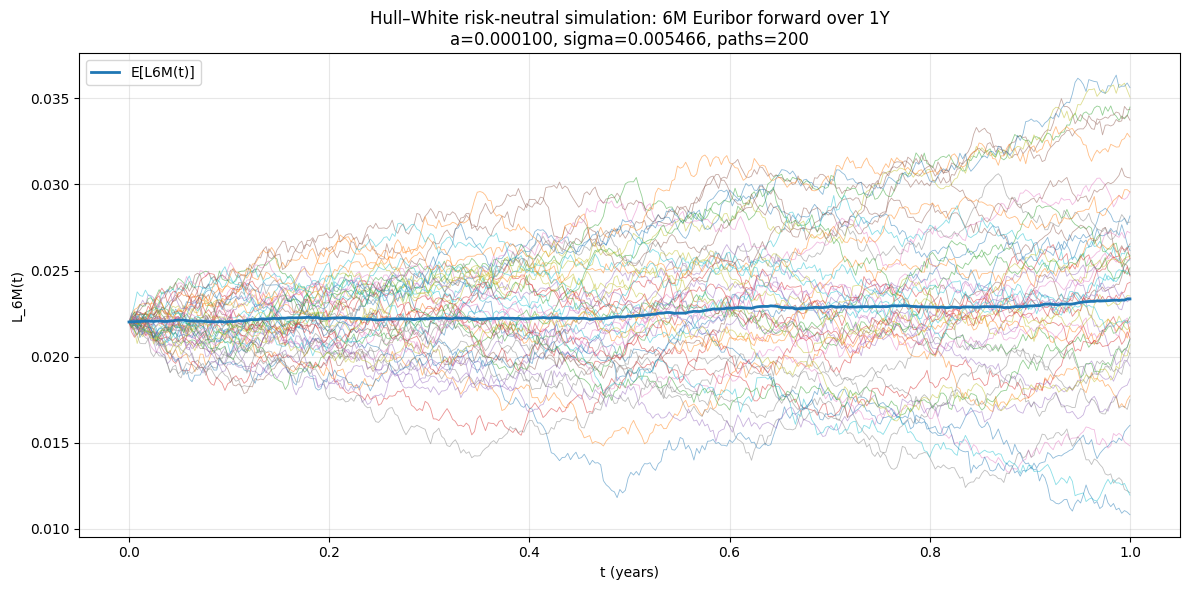

Mean 6M Euribor at t=1Y: 2.334902%
Std  6M Euribor at t=1Y: 0.587609%


In [46]:
plt.figure(figsize=(12,6))
plt.plot(times, L6[:50, :].T, lw=0.6, alpha=0.5)
plt.plot(times, L6.mean(axis=0), lw=2.0, label="E[L6M(t)]")
plt.title(f"Hull–White risk-neutral simulation: 6M Euribor forward over 1Y\n"
          f"a={a:.6f}, sigma={sigma:.6f}, paths={n_paths}")
plt.xlabel("t (years)")
plt.ylabel("L_6M(t)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

print(f"Mean 6M Euribor at t=1Y: {L6[:, -1].mean():.6%}")
print(f"Std  6M Euribor at t=1Y: {L6[:, -1].std(ddof=1):.6%}")

### ZCB 1Y COMPUTES ANALYTICALLY AND MONTE CARLO

Under the risk-neutral measure $\mathbb{Q}$, the time-0 price of a ZCB maturing at $T=1$ is
$$
P(0,1)=\mathbb{E}^{\mathbb{Q}}\!\left[\exp\!\left(-\int_0^1 r(u)\,du\right)\right].
$$

**Analytical (curve) price.**  
In the curve-fitted Hull–White setup, the initial discount curve is an input, so the analytical benchmark is simply the curve discount factor:
$$
P_{\text{curve}}(0,1)=P(0,1).
$$

**Monte Carlo price.**  
We simulate short-rate paths $r(t)=x(t)+\phi(t)$ on a grid $t_0,\dots,t_n$ and approximate the integral with the trapezoidal rule:
$$
\int_0^1 r(u)\,du \approx \Delta t\left(\tfrac12 r(t_0)+\sum_{k=1}^{n-1}r(t_k)+\tfrac12 r(t_n)\right).
$$
For each path $p$ we compute the discount factor
$$
D^{(p)}(0,1)=\exp\!\left(-\int_0^1 r^{(p)}(u)\,du\right),
$$
and the Monte Carlo estimator is
$$
\widehat{P}_{MC}(0,1)=\frac{1}{N}\sum_{p=1}^N D^{(p)}(0,1).
$$

In [47]:
def inst_fwd_rate(P, t, eps=1/365):
    t = float(t)
    t1 = max(t - eps, 1e-8)
    t2 = t + eps
    return - (np.log(float(P(t2))) - np.log(float(P(t1)))) / (t2 - t1)

def hw_phi(P, a, sigma, t):
    t = max(float(t), 1e-8)
    f0t = inst_fwd_rate(P, t)
    return float(f0t + (sigma*sigma/(2.0*a*a)) * (1.0 - np.exp(-a*t))**2)

def simulate_hw_paths(P, a, sigma, T=1.0, dt=1/365, n_paths=20000, seed=123):
    n_steps = int(round(T/dt))
    times = np.linspace(0.0, T, n_steps + 1)

    rng = np.random.default_rng(seed)
    Z = rng.standard_normal((n_paths, n_steps))

    exp_ad = np.exp(-a*dt)
    std = sigma * np.sqrt((1.0 - np.exp(-2.0*a*dt)) / (2.0*a))

    x = np.zeros((n_paths, n_steps + 1))
    for k in range(n_steps):
        x[:, k+1] = x[:, k]*exp_ad + std*Z[:, k]

    phi = np.array([hw_phi(P, a, sigma, t) for t in times])
    r_paths = x + phi  
    return times, r_paths

# Prezzo ZCB via Monte Carlo
def zcb_price_mc(times, r_paths):
    dt = float(times[1] - times[0])
    integ = dt * (0.5*r_paths[:,0] + r_paths[:,1:-1].sum(axis=1) + 0.5*r_paths[:,-1])
    disc = np.exp(-integ)
    return float(disc.mean()), disc

1Y ZCB price: curve=0.97834135 | MC=0.97833279 | diff=-0.086 bp


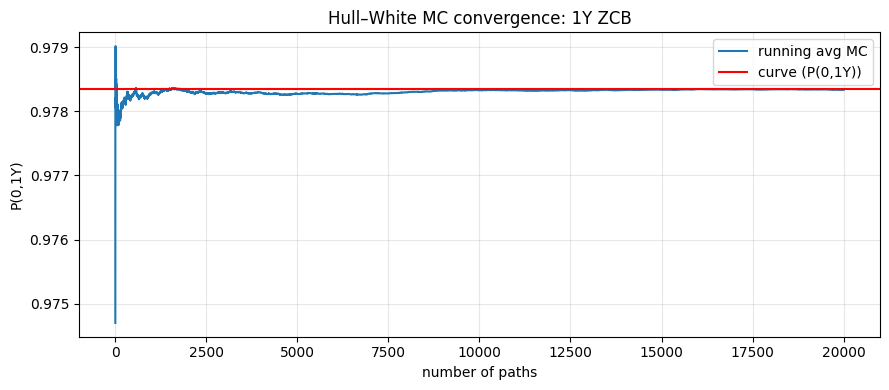

In [48]:
T = 1.0
dt = 1/365
n_paths = 20000
seed = 123

times, r_paths = simulate_hw_paths(P, a_cal, sigma_cal, T=T, dt=dt, n_paths=n_paths, seed=seed)

P_curve = float(P(T))              
P_mc, disc = zcb_price_mc(times, r_paths)

print(f"1Y ZCB price: curve={P_curve:.8f} | MC={P_mc:.8f} | diff={(P_mc-P_curve)*1e4:+.3f} bp")

running = np.cumsum(disc) / np.arange(1, disc.size + 1)

plt.figure(figsize=(9,4))
plt.plot(np.arange(1, disc.size+1), running, label="running avg MC")
plt.axhline(P_curve, linestyle="-",color = "red", label="curve (P(0,1Y))")
plt.xlabel("number of paths")
plt.ylabel("P(0,1Y)")
plt.title("Hull–White MC convergence: 1Y ZCB")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

**Analytical (curve-fitted) value.**  
$$
P_{\text{curve}}(0,1)=P(0,1)=0.97834135.
$$

**Monte Carlo estimator.**  
$$
\widehat{P}_{MC}(0,1)=\frac{1}{N}\sum_{p=1}^{N}\exp\!\left(-\int_0^{1} r^{(p)}(u)\,du\right)=0.97833279.
$$

**Comparison and interpretation.**  
The difference is very small:
$$
\widehat{P}_{MC}(0,1)-P_{\text{curve}}(0,1)\approx -0.086 \text{ bp}.
$$
The convergence plot shows the Monte Carlo estimate stabilizing around the analytical curve price as the number of paths increases. 
